# 14 — Do the deployed intervals hold up? FD004 coverage, and a near-failure check

**Why this notebook exists.** The export script computes a conformal correction for FD004's RSF interval (36.00 cycles), but its coverage on FD004's test set had never been checked; it was the one open item in the interval story. This notebook closes it.

**What it does.** It loads the **deployed** bundles from `models/fd001/` and `models/fd004/`, nothing is retrained, and scores every official test engine through `inference.predict`, the same function the API and the dashboard call. Then it measures, for both 90% intervals the API returns:
- the **Weibull AFT** interval: the deployed interval when this check was run (returned as `weibull_interval_90`; notebook 15 replaced it);
- the **calibrated RSF** interval: supplementary, conformally corrected.

It reports overall coverage, coverage by true-RUL band, and on which side the misses fall.

**FD001 is included as a reproduction check.** Notebook 12 measured FD001 on the same deployed recipe (RSF-cal 90.0%, Weibull 89.0%; above the 125-cycle cap 27.3% vs 90.9%). If this notebook reproduces those numbers, the method is right and the FD004 numbers can be trusted.

**Ground rule.** This is evaluation on the official test sets, so nothing here is used to *choose* a different deployed interval; doing that would tune on the test set. Any change it motivates must be selected on training data (cross-conformal folds) first.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sksurv.metrics import concordance_index_censored

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, evaluation, inference, plotting

plotting.style()
SUBSETS = ["FD001", "FD004"]
CAP = 125
DATA_DIR = Path("..") / "data" / "raw"
MODELS_DIR = Path("..") / "models"
PROCESSED_DIR = Path("..") / "data" / "processed"

## 1. Score every test engine with the deployed models

In [2]:
rows = []
for subset in SUBSETS:
    bundle = inference.load_deployment_bundle(MODELS_DIR / subset.lower())
    data_loading.download_cmapss(subset, data_dir=DATA_DIR)
    cmapss = data_loading.load_subset(subset, data_dir=DATA_DIR)
    true_rul = cmapss.rul.set_index("unit_number")["RUL"]
    for unit, engine in cmapss.test.groupby("unit_number"):
        engine = engine.sort_values("time_cycles")
        r = inference.predict(bundle, engine[["time_cycles"] + bundle.raw_passthrough_cols])
        # Weibull's own interval. (confidence_interval_90 now serves the combined
        # interval selected in notebook 15, so it must not be read as "Weibull".)
        w_lo, w_hi = r["weibull_interval_90"]
        r_lo, r_hi = r["rsf_calibrated_interval_supplementary"]["interval_90"]
        rows.append(dict(subset=subset, unit=unit, true_rul=true_rul.loc[unit],
                         pred=r["predicted_rul_cycles"], weibull_lo=w_lo, weibull_hi=w_hi,
                         rsf_cal_lo=r_lo, rsf_cal_hi=r_hi, q=bundle.rsf_interval_correction))
    print(f"{subset}: {cmapss.test.unit_number.nunique()} test engines scored, q = {bundle.rsf_interval_correction:.2f}")

res = pd.DataFrame(rows)
for name in ["weibull", "rsf_cal"]:
    res[f"{name}_covered"] = res.true_rul.between(res[f"{name}_lo"], res[f"{name}_hi"])
    res[f"{name}_width"] = res[f"{name}_hi"] - res[f"{name}_lo"]
    # A miss "below" means the true RUL is under the lower bound: the interval
    # promised more life than the engine had -- the dangerous direction.
    res[f"{name}_miss_dangerous"] = res.true_rul < res[f"{name}_lo"]
res.to_csv(PROCESSED_DIR / "interval_coverage_check.csv", index=False)

FD001: 100 test engines scored, q = 5.00


FD004: 248 test engines scored, q = 36.00


## 2. Point-estimate metrics of the deployed RSF

In [3]:
def point_metrics(g):
    y, p = g.true_rul.to_numpy(float), g.pred.to_numpy(float)
    cindex = concordance_index_censored(np.ones(len(g), bool), y, -p)[0]
    return pd.Series({"engines": len(g), "C-index": cindex,
                      "NASA / engine": evaluation.nasa_score_mean(y, p),
                      "MAE": evaluation.mae(y, p), "RMSE": evaluation.rmse(y, p),
                      "late rate": evaluation.late_prediction_rate(y, p),
                      "share above cap": (g.true_rul > CAP).mean()})

res.groupby("subset").apply(point_metrics, include_groups=False).round(3)

,engines,C-index,NASA / engine,MAE,RMSE,late rate,share above cap
subset,,,,,,,
FD001,100.0,0.877,3.119,10.436,14.241,0.600,0.11
FD004,248.0,0.862,22.413,20.655,28.206,0.484,0.27


FD001 matches the deployed figures already reported (C-index 0.864, NASA ≈ 4.0 per engine, MAE 11.3). For FD004 these are the first numbers from the **deployed** model (leaf=5, all 249 training engines); the README's earlier FD004 row came from notebook 10's untuned recipe. Note the last column: 27% of FD004's test engines have more life left than the 125-cycle cap the models were trained with, against 11% for FD001.

## 3. Overall coverage, and the reproduction check

In [4]:
def coverage(g):
    out = {}
    for name, label in [("weibull", "Weibull"), ("rsf_cal", "RSF calibrated")]:
        out[f"{label} coverage"] = g[f"{name}_covered"].mean()
        out[f"{label} width"] = g[f"{name}_width"].mean()
    return pd.Series(out)

overall = res.groupby("subset").apply(coverage, include_groups=False).round(3)
overall

,Weibull coverage,Weibull width,RSF calibrated coverage,RSF calibrated width
subset,,,,
FD001,0.890,98.555,0.900,59.560
FD004,0.806,98.801,0.879,122.556


In [5]:
fd001 = overall.loc["FD001"]
above = res[(res.subset == "FD001") & (res.true_rul > CAP)]
assert abs(fd001["RSF calibrated coverage"] - 0.900) < 0.011 and abs(fd001["Weibull coverage"] - 0.890) < 0.011
assert abs(above.rsf_cal_covered.mean() - 0.273) < 0.01 and abs(above.weibull_covered.mean() - 0.909) < 0.01
print("FD001 reproduces notebook 12 (90.0% / 89.0% overall; 27.3% / 90.9% above the cap)")

FD001 reproduces notebook 12 (90.0% / 89.0% overall; 27.3% / 90.9% above the cap)


## 4. Coverage by true remaining life

In [6]:
BANDS = [0, 25, 50, 75, 100, 125, np.inf]
LABELS = ["0-25", "26-50", "51-75", "76-100", "101-125", ">125"]
res["band"] = pd.cut(res.true_rul, BANDS, labels=LABELS)
by_band = (res.groupby(["subset", "band"], observed=True)
              .agg(engines=("unit", "size"),
                   weibull_cov=("weibull_covered", "mean"), rsf_cal_cov=("rsf_cal_covered", "mean"),
                   weibull_width=("weibull_width", "mean"), rsf_cal_width=("rsf_cal_width", "mean"))
              .round(3))
by_band

engines  weibull_cov  rsf_cal_cov  weibull_width  \
subset band                                                        
FD001  0-25          19        0.579        1.000         44.521   
       26-50         14        1.000        1.000         60.129   
       51-75         10        1.000        1.000         91.520   
       76-100        24        0.958        0.958        111.300   
       101-125       22        0.955        0.955        136.573   
       >125          11        0.909        0.273        143.345   
FD004  0-25          50        0.540        1.000         44.756   
       26-50         30        0.933        1.000         64.657   
       51-75         28        0.964        1.000         95.404   
       76-100        40        0.950        1.000        106.262   
       101-125       33        0.939        1.000        121.924   
       >125          67        0.731        0.552        139.999   

                rsf_cal_width  
subset band                    
FD001  0-25            32.053  
       26-50           53.786  
       51-75           81.900  
       76-100          74.750  
       101-125         60.364  
       >125            59.364  
FD004  0-25           106.180  
       26-50          128.367  
       51-75          141.464  
       76-100         139.675  
       101-125        127.697  
       >125           111.522

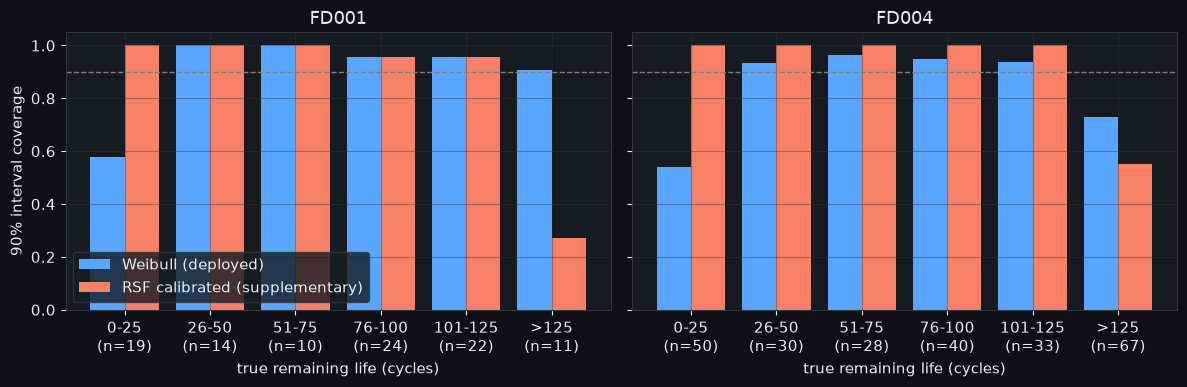

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, subset in zip(axes, SUBSETS):
    b = by_band.loc[subset]
    x = np.arange(len(b))
    ax.bar(x - 0.2, b.weibull_cov, 0.4, label="Weibull (deployed)")
    ax.bar(x + 0.2, b.rsf_cal_cov, 0.4, label="RSF calibrated (supplementary)")
    ax.axhline(0.9, color="grey", ls="--", lw=1)
    ax.set_xticks(x, [f"{l}\n(n={n})" for l, n in zip(b.index, b.engines)])
    ax.set_title(subset); ax.set_xlabel("true remaining life (cycles)")
axes[0].set_ylabel("90% interval coverage"); axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

## 5. Which side do the misses fall on?

In [8]:
def misses(g):
    out = {"engines": len(g)}
    for name, label in [("weibull", "Weibull"), ("rsf_cal", "RSF cal")]:
        missed = g[~g[f"{name}_covered"]]
        out[f"{label}: promised too much life"] = int(missed[f"{name}_miss_dangerous"].sum())
        out[f"{label}: promised too little"] = int((~missed[f"{name}_miss_dangerous"]).sum())
    return pd.Series(out)

print("All test engines"); display(res.groupby("subset").apply(misses, include_groups=False))
print("Engines within 25 cycles of failure"); display(res[res.true_rul <= 25].groupby("subset").apply(misses, include_groups=False))

All test engines


,engines,Weibull: promised too much life,Weibull: promised too little,RSF cal: promised too much life,RSF cal: promised too little
subset,,,,,
FD001,100,8,3,1,9
FD004,248,23,25,0,30


Engines within 25 cycles of failure


,engines,Weibull: promised too much life,Weibull: promised too little,RSF cal: promised too much life,RSF cal: promised too little
subset,,,,,
FD001,19,8,0,0,0
FD004,50,23,0,0,0


## 6. Findings

**FD004's calibrated RSF interval (the open item).** 87.9% coverage against a 90% target, so the 36-cycle correction roughly does its job in aggregate. But it does it bluntly: the interval is 24% *wider* than Weibull's (122.6 vs 98.8 cycles), covers 100% of engines up to the cap, and only 55% of the 67 engines above it. It's the same structural failure notebook 12 found on FD001 (27%): a uniform correction can't create support above the training cap. FD004 has 6× as many such engines, so the correction had to be large, and it widened every interval to pay for them. Conclusion: it stays supplementary, exactly as on FD001.

**FD004's deployed Weibull interval.** 80.6% coverage, under target, and short in two places: 73% above the cap and 54% within 25 cycles of failure.

**New: the deployed interval fails on near-failure engines, on both subsets.** For engines within 25 cycles of failure, Weibull's 90% interval covers only 58% (FD001, 11 of 19) and 54% (FD004, 27 of 50). Every one of those misses is on the dangerous side: the true remaining life is *below* the lower bound, so the interval promised more life than the engine had. The calibrated RSF interval covers all of these engines on both subsets. Notebook 12's subgroup check looked at the long-lived end and found that Weibull is needed there. This check looks at the short end and finds that Weibull fails there, where a late call matters most.

**The two intervals fail on opposite ends.** Weibull is reliable for long-lived engines and unreliable near failure; calibrated RSF is the reverse. Neither is a sound 90% interval across the whole range of remaining life.

**What this does and doesn't change.** Nothing in the deployment changes from this notebook, because it uses the test set (see the ground rule above). The obvious candidate is to combine the two: take the lower bound from the calibrated RSF and the upper bound from Weibull, or their union. That has to be calibrated and selected with cross-conformal folds on *training* engines, the same way notebook 12 calibrated RSF, and only then confirmed here. Until that's done, the dashboard and API should not present the Weibull lower bound as a safe floor for engines that the point estimate already puts close to failure.

**Follow-up:** `notebooks/15_interval_fix.ipynb` does this. The combined interval (lower bound from the more cautious model, upper bound from Weibull) was selected on training data and is now the deployed interval.